# 08 · Reverse Engineering Generator: Struktur, Digit, Snap & Faktor Laten

Notebook ini menindaklanjuti diskusi empat topik:

| Topik | Pertanyaan | Bagian |
|---|---|---|
| Reverse engineering generator | Bagaimana fitur-fitur "dibuat"? Apa yang menggerakkannya? | 1 |
| Resep target | Bagaimana target terbentuk dari sifat-sifat nasabah? | 1 |
| Digit extraction | Apakah pola digit/pembulatan angka membawa sinyal? | 2 |
| Snap features | Apakah selisih nilai aktual vs nilai "seharusnya" menurut aturan grid membawa sinyal? | 3 |

Dari bagian 1, muncul satu ide fitur tambahan: **skor sifat laten** (bagian 4). Bagian 5 menguji blok **snap** dan **laten** dengan protokol berpasangan yang sama seperti notebook 05/06, terhadap model terbaik tunggal kita (`lgbm_tuned`).

> Waktu jalan ±15–30 menit (tahap A: 3 blok × 3 seed; tahap B hanya untuk blok yang menjanjikan).

In [1]:
import gc
import json
import time
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import eda_utils as E
import features as F
import features_v3 as V3
import modeling as M

E.setup_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(60)

meta = json.loads((M.FEAT_DIR / "features_v1.json").read_text())
train = pl.read_parquet(M.FEAT_DIR / "train_v1.parquet")
test = pl.read_parquet(M.FEAT_DIR / "test_v1.parquet")
FEAT, CATS = meta["features"], meta["categorical"]
y = train["target"].to_numpy()
SEG = train["segment"].to_numpy()
NOISE = E.ks_noise_floor(y)
base = M.run_from_disk("lgbm_tuned", y)
PARAMS = {k: v for k, v in base["params"].items() if k != "random_state"}
print(f"Pembanding: lgbm_tuned ({base['meta'].get('config')}) | KS OOF {base['ks_oof']:.4f} | noise floor KS {NOISE:.4f}")

Pembanding: lgbm_tuned (reg. kuat + extra_trees) | KS OOF 0.5227 | noise floor KS 0.0144


## 1. Struktur generator: sifat laten & resep target

**Uji korelasi bersyarat.** Kalau dua fitur berkorelasi **di dalam** kelompok lancar dan di dalam kelompok gagal bayar secara terpisah, hubungan keduanya tidak hanya lewat target. Keduanya digerakkan oleh "sesuatu" yang sama, yaitu sifat laten nasabah.

Ada satu pola lain yang dicari: dua fitur yang **independen** secara keseluruhan tetapi berkorelasi di dalam kelompok gagal bayar. Ini tanda keduanya adalah **penyebab independen** dari gagal bayar. Polanya disebut efek *explaining away* (paradoks Berkson): di antara nasabah gagal bayar, yang skor bironya bagus "harus" punya sebab lain.

In [2]:
PAIRS = [("ec_price_premium_mean", "rp_late_share"), ("ec_price_premium_mean", "bu_all_score_mean"),
         ("bu_all_score_mean", "rp_late_share"), ("ec_price_premium_mean", "ec_order_surge_30d"),
         ("ec_order_surge_30d", "bu_all_score_mean")]
rows = []
for a, b in PAIRS:
    r = dict(fitur_1=a, fitur_2=b)
    for lab, mask in [("semua", np.ones(len(y), bool)), ("lancar", y == 0), ("gagal_bayar", y == 1)]:
        sub = train.filter(pl.Series(mask)).select(a, b).drop_nulls()
        r[f"corr_{lab}"] = float(np.corrcoef(sub[a], sub[b])[0, 1])
    rows.append(r)
pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(3))

fitur_1,fitur_2,corr_semua,corr_lancar,corr_gagal_bayar
str,str,f64,f64,f64
"""ec_price_premium_mean""","""rp_late_share""",0.447,0.375,0.368
"""ec_price_premium_mean""","""bu_all_score_mean""",-0.01,0.049,0.127
"""bu_all_score_mean""","""rp_late_share""",-0.309,-0.255,-0.236
"""ec_price_premium_mean""","""ec_order_surge_30d""",0.462,0.434,0.41
"""ec_order_surge_30d""","""bu_all_score_mean""",-0.007,0.038,0.067


**Cara membaca:**

- **Premium ↔ telat bayar** berkorelasi kira-kira sama kuat di kedua kelompok. Artinya ada satu sifat laten, semacam "disiplin finansial", yang membuat nasabah sekaligus membayar lebih mahal saat belanja **dan** sering telat membayar cicilan.
- **Premium ↔ skor biro** ≈ 0 secara keseluruhan, tetapi positif di kelompok gagal bayar. Ini jejak dua penyebab independen. Sifat "perilaku" (tercermin di premium) dan sifat "kelayakan kredit" (tercermin di skor biro) masing-masing **sendiri-sendiri** menaikkan risiko.

**Resep target yang konsisten dengan semua bukti:** beberapa sifat laten independen → peluang gagal bayar = sigmoid(gabungan aditif sifat-sifat itu) → target diundi dari peluang tersebut.

Bukti pendukung dari notebook sebelumnya:
1. Regresi logistik hanya sedikit di bawah GBDT (notebook 07).
2. Pohon kecil teregularisasi menang (notebook 06).
3. Empat algoritma berbeda sampai di KS yang hampir sama.

Konsekuensinya, fitur yang kita punya hanyalah **cerminan berisik** dari sifat laten, dan target mengandung keacakan pengundian. Keduanya membatasi KS maksimum yang bisa dicapai.

## 2. Digit extraction & pembulatan

Kalau generator membulatkan angka secara berbeda untuk nasabah berisiko (misalnya pendapatan "dikarang" bulat), pola digit akan membawa sinyal. Diuji: jumlah nol di belakang angka, digit terakhir yang signifikan, dan pola harga e-commerce per nasabah.

In [3]:
app = E.load("train_applications").join(E.load("customer_profiles"), on="customer_id", how="left")   # left join menjaga urutan baris
assert app["application_id"].equals(train["application_id"])

def trailing_zeros(v):
    v = np.asarray(v, dtype=np.int64); out = np.zeros(len(v), int)
    for k in range(1, 10):
        out += (v % (10 ** k) == 0)
    return out

digit_rows = []
for col in ["loan_amount", "declared_monthly_income", "proposed_monthly_installment"]:
    v = app[col].to_numpy(); tz = trailing_zeros(v)
    last = (v // (10 ** int(np.median(tz)))) % 10
    digit_rows += [dict(fitur=f"{col}: jumlah nol di belakang", ks=E.ks_stat(y, tz)),
                   dict(fitur=f"{col}: digit terakhir signifikan", ks=E.ks_stat(y, last))]
cut_tr = app.select("customer_id", pl.col("decision_datetime").alias("cutoff"))
ec = (E.lazy("ecommerce_transactions").join(cut_tr.lazy(), on="customer_id")
        .filter(pl.col("transaction_datetime") < pl.col("cutoff"))
        .group_by("customer_id").agg(
            porsi_harga_kelipatan_10rb=(pl.col("item_total") % 10000 == 0).mean(),
            porsi_harga_kelipatan_5rb=(pl.col("item_total") % 5000 == 0).mean(),
            porsi_harga_berakhiran_9rb=(((pl.col("item_total") // 1000) % 10) == 9).mean())
        .collect())
ecd = app.select("customer_id").join(ec, on="customer_id", how="left")
for c in ec.columns[1:]:
    digit_rows.append(dict(fitur=f"e-commerce: {c}", ks=E.ks_stat(y, ecd[c].to_numpy())))
digits = pl.DataFrame(digit_rows).with_columns(pl.col("ks").round(4), di_atas_noise=pl.col("ks") > NOISE)
print(f"Noise floor KS: {NOISE:.4f}")
digits

Noise floor KS: 0.0144


fitur,ks,di_atas_noise
str,f64,bool
"""loan_amount: jumlah nol di belakang""",0.0012,false
"""loan_amount: digit terakhir signifikan""",0.0086,false
"""declared_monthly_income: jumlah nol di belakang""",0.0015,false
"""declared_monthly_income: digit terakhir signifikan""",0.0074,false
"""proposed_monthly_installment: jumlah nol di belakang""",0.0051,false
"""proposed_monthly_installment: digit terakhir signifikan""",0.0096,false
"""e-commerce: porsi_harga_kelipatan_10rb""",0.0122,false
"""e-commerce: porsi_harga_kelipatan_5rb""",0.0202,true
"""e-commerce: porsi_harga_berakhiran_9rb""",0.0138,false


**Cara membaca:** semua fitur digit di bawah noise floor. Pembulatannya alami: pinjaman selalu kelipatan 100 ribu, harga kelipatan 1.000, dan ~10% kebetulan kelipatan 10× lebih besar, dengan default rate yang sama. Generator ini tidak meninggalkan jejak digit yang terkait target, jadi jalur ini **ditutup**.

## 3. Snap: suku bunga aktual vs suku bunga "seharusnya"

Suku bunga hanya punya 5 tingkat: 16, 20, 24, 28, 32%. Tingkatnya sangat ditentukan skor biro, tetapi tidak sepenuhnya. Pertanyaannya: apakah **penyimpangan** dari tingkat yang diharapkan membawa informasi privat pemberi pinjaman?

**Peta "skor → suku bunga yang diharapkan"** dipelajari hanya dari **pengajuan lama yang disetujui sebelum 1 Januari 2025** (keputusan paling awal di train/test), sehingga patuh aturan cutoff. Peta ini lalu diterapkan ke:
- **aplikasi ini:** residu = suku bunga aktual − suku bunga yang diharapkan dari skor biro aplikasi ini;
- **pengajuan lama nasabah yang sama** (sebelum cutoff): residu historis rata-rata, terakhir, dan maksimum.

Peta harga dari 122,646 pengajuan lama sebelum 2025-01-01 | 62 titik skor


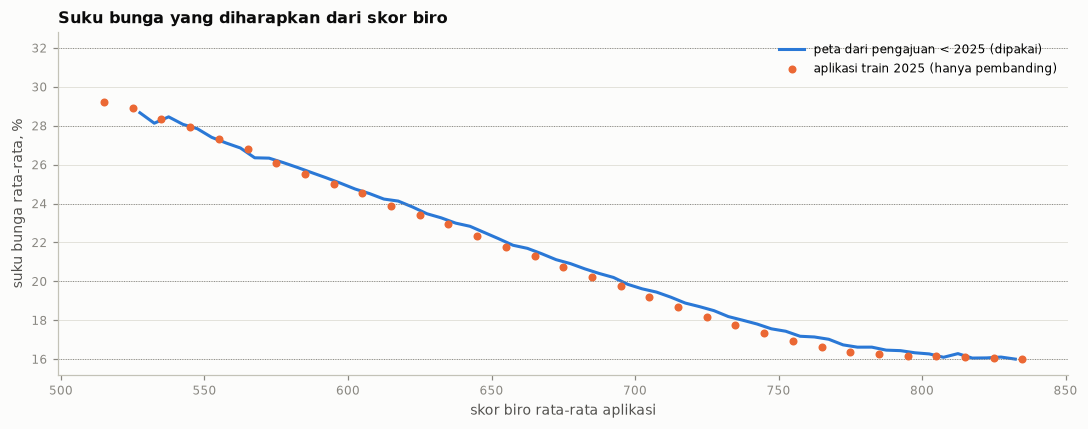

In [4]:
pa, bo = E.load("previous_applications"), E.load("bureau_observations")
first = min(E.load(n, columns=["decision_datetime"])["decision_datetime"].min() for n in ("train_applications", "test_applications"))
PMAP = V3.pricing_map(pa, bo, first)
print(f"Peta harga dari {PMAP['n_apps']:,} pengajuan lama sebelum {first.date()} | {len(PMAP['centers'])} titik skor")

d = train.select("annual_interest_rate", "bu_score_mean").drop_nulls()
s25 = (d.with_columns(b=(pl.col("bu_score_mean") / 10).floor() * 10 + 5)
         .group_by("b").agg(n=pl.len(), rate=pl.col("annual_interest_rate").mean()).filter(pl.col("n") >= 30).sort("b"))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(PMAP["centers"], PMAP["rates"] * 100, color=E.SERIES[0], lw=2, label="peta dari pengajuan < 2025 (dipakai)")
ax.scatter(s25["b"], s25["rate"] * 100, color=E.SERIES[1], s=18, zorder=3, label="aplikasi train 2025 (hanya pembanding)")
for t in (16, 20, 24, 28, 32):
    ax.axhline(t, color="grey", lw=0.6, ls=":")
ax.set_xlabel("skor biro rata-rata aplikasi"); ax.set_ylabel("suku bunga rata-rata, %")
ax.set_title("Suku bunga yang diharapkan dari skor biro", loc="left"); ax.legend()
plt.tight_layout(); plt.show()

In [5]:
def cut_of(name):
    return E.load(name).select("customer_id", pl.col("decision_datetime").alias("cutoff"))

SN_TR = V3.snap_features(train, pa, bo, cut_of("train_applications"), PMAP)
SN_TE = V3.snap_features(test, pa, bo, cut_of("test_applications"), PMAP)
assert SN_TR["application_id"].equals(train["application_id"]) and SN_TE["application_id"].equals(test["application_id"])

# apakah suku bunga membawa sinyal DI DALAM kelompok skor yang sama?
tmp = train.select("target", "annual_interest_rate", "bu_score_mean").with_columns(sb=E.qbin("bu_score_mean", 20)).drop_nulls("sb")
ks_in, ns = [], []
for (g,), part in tmp.group_by(["sb"]):
    ks_in.append(E.ks_stat(part["target"].to_numpy(), part["annual_interest_rate"].to_numpy())); ns.append(part.height)
noise_bin = E.ks_noise_floor(tmp.filter(pl.col("sb") == 0)["target"].to_numpy())
print(f"KS suku bunga di dalam 20 kelompok skor (rata-rata): {np.average(ks_in, weights=ns):.4f} | noise per kelompok ≈ {noise_bin:.4f}")
uni_sn = pl.DataFrame([dict(fitur=c, ks=E.ks_stat(y, SN_TR[c].to_numpy()), null=SN_TR[c].null_count() / SN_TR.height)
                       for c in SN_TR.columns[1:]]).with_columns(pl.col("ks", "null").round(4))
uni_sn

KS suku bunga di dalam 20 kelompok skor (rata-rata): 0.0540 | noise per kelompok ≈ 0.0421


fitur,ks,null
str,f64,f64
"""sn_rate_expected""",0.2524,0.0
"""sn_rate_resid""",0.0733,0.0
"""sn_tier_resid""",0.0504,0.0
"""sn_hist_resid_mean""",0.0423,0.3348
"""sn_hist_resid_last""",0.046,0.3348
"""sn_hist_resid_max""",0.044,0.3348
"""sn_hist_n""",0.0422,0.3348
"""sn_resid_vs_hist""",0.0708,0.3348


**Cara membaca:**

- **Grafik:** peta dari data lama (garis) dan data 2025 (titik) berimpit. Aturan harga pemberi pinjaman stabil, jadi peta yang dipelajari dari masa lalu sah dipakai untuk 2025.
- **KS di dalam kelompok skor:** suku bunga masih sedikit di atas noise. Ada informasi privat, tetapi kecil.
- **Residu:** KS univariat residu kecil (±0,07). Model juga sudah punya suku bunga dan semua skor biro, jadi residu ini mungkin tidak menambah banyak. Uji di bagian 5 yang memutuskan.

## 4. Skor sifat laten

Dari bagian 1, sifat laten tercermin di banyak fitur sekaligus. Skor laten menggabungkan cerminan-cerminan itu menjadi satu estimasi yang lebih bersih:

1. Setiap proksi diubah menjadi skor normal (berbasis kuantil, tahan outlier).
2. Bobot = muatan komponen utama pertama (PCA) dari korelasi antar-proksi. Bobotnya **tidak memakai target**: transformasi dan bobot di-*fit* di fitur train saja, lalu diterapkan ke test.
3. Skor = rata-rata tertimbang dari proksi yang **tersedia** untuk nasabah itu, sehingga nasabah tanpa riwayat cicilan tetap punya skor.

Tiga skor dibentuk: `lt_behavior` (premium, telat bayar, lonjakan belanja, keterbaruan, lonjakan pengeluaran rekening), `lt_credit` (skor biro, suku bunga, tunggakan & inquiry biro, utilisasi), dan `lt_all` (semuanya).

In [6]:
LFIT = V3.latent_fit(train)
LT_TR, LT_TE = V3.latent_features(train, LFIT), V3.latent_features(test, LFIT)
print("Porsi varians yang dijelaskan PC1:", {k: round(v["explained"], 3) for k, v in LFIT.items()})
display(V3.loadings_table(LFIT).filter(pl.col("faktor") != "all").with_columns(pl.col("muatan").round(3)))
REF = ["ec_price_premium_mean", "rp_late_share", "bu_all_score_mean", "annual_interest_rate"]
uni_lt = pl.DataFrame([dict(fitur=c, ks=E.ks_stat(y, LT_TR[c].to_numpy())) for c in LT_TR.columns[1:]]
                      + [dict(fitur=f"(acuan) {c}", ks=E.ks_stat(y, train[c].to_numpy())) for c in REF]).with_columns(pl.col("ks").round(4))
uni_lt

Porsi varians yang dijelaskan PC1: {'behavior': 0.53, 'credit': 0.545, 'all': 0.316}


faktor,proksi,muatan
str,str,f64
"""behavior""","""ec_price_premium_mean""",0.395
"""behavior""","""ec_price_premium_median""",0.385
"""behavior""","""rp_late_share""",0.32
"""behavior""","""rp_mean_dpd""",0.321
"""behavior""","""ec_order_surge_30d""",0.409
"""behavior""","""ec_spend_surge_30d""",0.395
"""behavior""","""ec_days_since_last_order""",-0.382
"""behavior""","""ac_out_surge_1m""",0.146
"""credit""","""bu_all_score_mean""",-0.522


fitur,ks
str,f64
"""lt_behavior""",0.4102
"""lt_behavior_coverage""",0.0476
"""lt_credit""",0.2487
"""lt_credit_coverage""",0.0008
"""lt_all""",0.4711
"""lt_all_coverage""",0.0421
"""lt_behavior_x_credit""",0.1744
"""(acuan) ec_price_premium_mean""",0.3652
"""(acuan) rp_late_share""",0.3183


**Cara membaca:** `lt_all` biasanya punya KS univariat **jauh lebih tinggi** dari fitur tunggal mana pun, karena noise tiap proksi saling meredam. Tetapi KS univariat tinggi tidak menjamin model membaik. GBDT sudah menggabungkan proksi-proksi itu sendiri, dan satu fitur gabungan yang sangat kuat bisa membuat pohon terlalu bergantung padanya. Uji berpasangan di bawah yang memutuskan.

## 5. Uji berpasangan terhadap `lgbm_tuned`

Parameter dan fold sama persis dengan `lgbm_tuned`. Satu-satunya perbedaan adalah blok fitur tambahan.

- **Tahap A (3 seed):** snap, laten, dan keduanya.
- **Tahap B (5 seed):** hanya untuk blok dengan Δ rata-rata positif.
- **Keputusan:** jelas (Δ ≥ 0,005) / tipis (Δ ≥ 0,002), keduanya mensyaratkan semua seed naik. Selain itu tidak.

In [7]:
BLK_DIR = M.FEAT_DIR / "blocks"; BLK_DIR.mkdir(parents=True, exist_ok=True)
for nm, (a, b) in {"snap": (SN_TR, SN_TE), "latent": (LT_TR, LT_TE)}.items():
    V3_final = lambda df: df.with_columns([pl.when(pl.col(c).is_finite()).then(pl.col(c)).otherwise(None).alias(c)
                                           for c, t in df.schema.items() if t in (pl.Float32, pl.Float64)])
    V3_final(a).write_parquet(BLK_DIR / f"{nm}_train.parquet"); V3_final(b).write_parquet(BLK_DIR / f"{nm}_test.parquet")
BLOCKS = {"snap": (pl.read_parquet(BLK_DIR / "snap_train.parquet"), pl.read_parquet(BLK_DIR / "snap_test.parquet")),
          "latent": (pl.read_parquet(BLK_DIR / "latent_train.parquet"), pl.read_parquet(BLK_DIR / "latent_test.parquet"))}

def with_blocks(names):
    tr, te, feats = train, test, list(FEAT)
    for n in names:
        a, b = BLOCKS[n]
        tr, te = tr.join(a, on="application_id", how="left"), te.join(b, on="application_id", how="left")
        feats += a.columns[1:]
    return tr, te, feats

EXPS = {"snap": ["snap"], "laten": ["latent"], "snap + laten": ["snap", "latent"]}
RUNS, CMP = {}, {}
for name, blks in EXPS.items():
    t = time.time()
    tr, te, feats = with_blocks(blks)
    RUNS[name] = M.train_lgb_cv(tr, te, feats, CATS, seeds=(42, 7, 2024), params=PARAMS, verbose=False)
    CMP[name] = M.compare_runs(base, RUNS[name], y, SEG)
    print(f"{name:14s} Δ per seed {[round(d, 4) for d in CMP[name]['per_seed']['delta']]} "
          f"| rata-rata {CMP[name]['delta_seed_mean']:+.4f} | {time.time() - t:.0f} detik")
    del tr, te; gc.collect()

snap           Δ per seed [-0.004, 0.0012, 0.0005] | rata-rata -0.0007 | 227 detik
laten          Δ per seed [-0.0018, 0.0026, -0.0013] | rata-rata -0.0002 | 179 detik
snap + laten   Δ per seed [-0.0002, -0.0005, -0.0021] | rata-rata -0.0009 | 169 detik


In [8]:
B_KEYS = []
for name, blks in EXPS.items():
    if CMP[name]["delta_seed_mean"] > 0:
        key = name + " (5 seed)"
        tr, te, feats = with_blocks(blks)
        RUNS[key] = M.train_lgb_cv(tr, te, feats, CATS, seeds=tuple(base["seeds"]), params=PARAMS, verbose=False)
        CMP[key] = M.compare_runs(base, RUNS[key], y, SEG)
        B_KEYS.append(key)
        del tr, te; gc.collect()
keys = list(EXPS) + B_KEYS
summary = pl.DataFrame([dict(eksperimen=k, n_fitur_baru=len(RUNS[k]["features"]) - len(FEAT), delta_oof=CMP[k]["delta_oof"],
                             delta_rata2=CMP[k]["delta_seed_mean"], seed_naik=f"{CMP[k]['n_seed_positive']}/{CMP[k]['per_seed'].height}",
                             keputusan=M.verdict(CMP[k], noise=0.0015)) for k in keys]).with_columns(pl.col(pl.Float64).round(4))
summary

eksperimen,n_fitur_baru,delta_oof,delta_rata2,seed_naik,keputusan
str,i64,f64,f64,str,str
"""snap""",8,-0.0033,-0.0007,"""2/3""","""tidak"""
"""laten""",7,-0.0018,-0.0002,"""1/3""","""tidak"""
"""snap + laten""",15,-0.0037,-0.0009,"""0/3""","""tidak"""


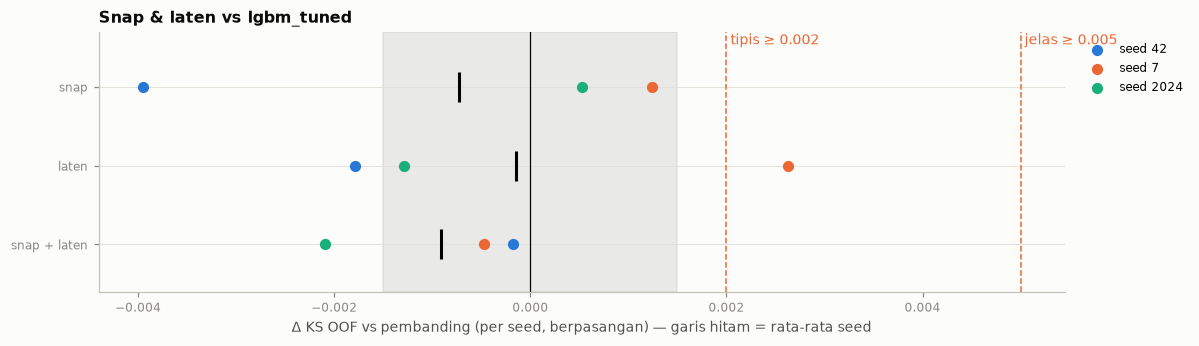

snap: porsi gain fitur baru 3.5% | teratas: sn_rate_expected (#9, 3.0%), sn_hist_resid_max (#95, 0.1%), sn_hist_resid_mean (#104, 0.1%)
laten: porsi gain fitur baru 37.7% | teratas: lt_all (#1, 22.7%), lt_behavior (#2, 11.5%), lt_behavior_x_credit (#9, 2.2%)
snap + laten: porsi gain fitur baru 35.8% | teratas: lt_all (#1, 22.1%), lt_behavior (#2, 7.7%), lt_behavior_x_credit (#8, 2.4%)


In [9]:
M.plot_paired_deltas(CMP, keys, noise=0.0015, title="Snap & laten vs lgbm_tuned")
for k in keys:
    new = [c for c in RUNS[k]["features"] if c not in FEAT]
    imp = RUNS[k]["importance"].with_columns(peringkat=pl.int_range(1, pl.len() + 1)).filter(pl.col("feature").is_in(new))
    print(f"{k}: porsi gain fitur baru {imp['gain_pct'].sum():.1f}% | teratas: "
          + ", ".join(f"{r['feature']} (#{r['peringkat']}, {r['gain_pct']:.1f}%)" for r in imp.head(3).iter_rows(named=True)))

**Cara membaca:** perhatikan kombinasi **porsi gain fitur baru** dan **Δ KS**. Kalau fitur baru mengambil porsi gain besar tetapi KS tidak naik (atau turun), fitur itu hanya **menggantikan** fitur lama yang membawa informasi sama, atau membuat model terlalu bergantung pada satu fitur gabungan.

In [10]:
passing = [k for k in B_KEYS if M.verdict(CMP[k], noise=0.0015) in ("jelas", "tipis")]
if passing:
    best = max(passing, key=lambda k: CMP[k]["delta_seed_mean"])
    M.save_run("lgbm_tuned_v3", train, test, RUNS[best], extra=dict(blocks=EXPS[best.replace(" (5 seed)", "")],
               delta_vs_lgbm_tuned=CMP[best]["delta_oof"], verdict=M.verdict(CMP[best], noise=0.0015)))
    print(f"Lolos: {best} → run disimpan sebagai lgbm_tuned_v3 (bisa dimasukkan ke ensemble).")
else:
    print("Tidak ada blok yang lolos → fitur v1 + lgbm_tuned tetap dipakai.")

Tidak ada blok yang lolos → fitur v1 + lgbm_tuned tetap dipakai.
